# 05 — Final test evaluation (owner: shared)

**Questions.** (1) Do the dev conclusions about configs A and B hold on the untouched FiQA **test** split?
(2) How good are the answers of the final system (config A, k = 5, τ = 0.60) on unseen questions?

**Setting.** Run **once** on 2026-11-11 with the configs fixed in `wiki/decisions/final_configs.md`; nothing was
tuned afterwards. Retrieval: all 648 test queries, full 57,638-doc corpus, A and B in the same session.
Generation: 100 test questions (seed 42), config A, all 100 sent to `openai/gpt-oss-120b`; `refused_by_tau`
marks the system's τ decision. Answers scored 1–3 with the E3 rubric: ChatGPT drafted scores and rationales, J and H
discussed each item and decided the final score (disclosed in `AI_USAGE.md`). No unanswerable test set (protocol), so correct refusal comes from dev only.

**Outputs.** `report/figures/final_*.pdf` and `report/tables/final_*.md`.

In [1]:
import csv
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO = Path.cwd().parent                      # run this notebook from notebooks/
sys.path.insert(0, str(REPO / "src"))
from finsight.rag import REFUSAL_TEXT
from finsight.report import AQUA, BLUE, INK_2, ORANGE, apply_style, save_figure, save_table

apply_style()
RESULTS = REPO / "experiments" / "results"
load = lambda p: json.loads((RESULTS / p).read_text())

metrics = {("A", "dev"): load("run_e2_005/metrics.json"), ("B", "dev"): load("run_e2_004/metrics.json"),
           ("A", "test"): load("final_a/metrics.json"), ("B", "test"): load("final_b/metrics.json")}
answers = {r["qid"]: r for r in map(json.loads, open(RESULTS / "final_gen_a/answers.jsonl"))}
with open(RESULTS / "final_gen_a/scoring.csv", newline="", encoding="utf-8-sig") as f:
    scores = list(csv.DictReader(f))
summary = load("final_gen_a/summary.json")
len(answers), len(scores), summary["refused_by_tau"]

(100, 100, 16)

## 1. Retrieval: dev vs. test (configs A and B)

Same metrics as E1/E2. Dev numbers are runs 005 (A) and 004 (B), measured in one session like the test runs.

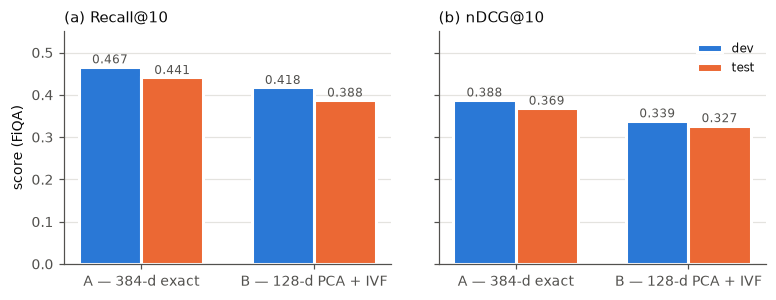

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8), sharey=True)
x, w = np.arange(2), 0.36
for ax, key, title in [(axes[0], "recall@10", "(a) Recall@10"), (axes[1], "ndcg@10", "(b) nDCG@10")]:
    for i, (split, color) in enumerate([("dev", BLUE), ("test", ORANGE)]):
        v = [metrics[(c, split)][key] for c in ("A", "B")]
        bars = ax.bar(x + (i - 0.5) * w, v, w, color=color, edgecolor="white", linewidth=2, label=split)
        for b, vi in zip(bars, v):
            ax.text(b.get_x() + b.get_width() / 2, vi + 0.008, f"{vi:.3f}", ha="center", color=INK_2, fontsize=8)
    ax.set_xticks(x, ["A — 384-d exact", "B — 128-d PCA + IVF"])
    ax.set_ylim(0, 0.55)
    ax.set_title(title, loc="left")
axes[0].set_ylabel("score (FiQA)")
axes[1].legend(loc="upper right")
fig.tight_layout(w_pad=2.5)
save_figure(fig, "final_dev_vs_test",
            "Retrieval quality of the two final configurations on FiQA dev (500 queries) and test (648 queries), "
            "full corpus. Both drop slightly on test; the gap between A and B is similar (Recall@10: −4.88 pt on "
            "dev, −5.35 pt on test).")
plt.show()

In [3]:
rows = []
for c, name in [("A", "A — 384-d exact"), ("B", "B — 128-d PCA + IVF 16")]:
    for split in ("dev", "test"):
        m = metrics[(c, split)]
        rows.append({"Config": name, "Split": split, "Queries": m["n_queries"],
                     "Recall@5": f"{m['recall@5']:.4f}", "Recall@10": f"{m['recall@10']:.4f}",
                     "nDCG@10": f"{m['ndcg@10']:.4f}", "MRR@10": f"{m['mrr@10']:.4f}",
                     "p95 (ms)": f"{m['latency_p95_ms']:.3f}", "Memory (MB)": f"{m['index_memory_mb']:.2f}"})
print(save_table(rows, "final_retrieval"))

| Config | Split | Queries | Recall@5 | Recall@10 | nDCG@10 | MRR@10 | p95 (ms) | Memory (MB) |
|---|---|---|---|---|---|---|---|---|
| A — 384-d exact | dev | 500 | 0.3797 | 0.4665 | 0.3881 | 0.4532 | 2.700 | 84.43 |
| A — 384-d exact | test | 648 | 0.3671 | 0.4413 | 0.3687 | 0.4451 | 11.630 | 84.43 |
| B — 128-d PCA + IVF 16 | dev | 500 | 0.3343 | 0.4178 | 0.3388 | 0.3956 | 0.089 | 28.14 |
| B — 128-d PCA + IVF 16 | test | 648 | 0.3258 | 0.3878 | 0.3275 | 0.4060 | 0.080 | 28.14 |



**Latency caveat.** During the test run the machine was under background load (load average ≈ 9.8).
Multithreaded TorchKNN (A) slowed to p95 11.6 ms (dev 2.7 ms); B's small FAISS search did not (0.080 vs 0.089 ms).
The test speed-up (~145×) is therefore inflated; we report the dev same-session **30×** as the speed result and
use test for accuracy only. Not re-run, by protocol.

## 2. Generation: what happens to the 100 test questions

System order: τ check first (top-1 < 0.60 → refuse without the LLM), then the LLM may still refuse with
`REFUSAL_TEXT`. Rubric labels for LLM refusals: `refused` = the 5 docs really lack the answer; `refused-wrongly`
= they contain it.

In [4]:
def outcome(r):
    if r["refused_by_tau"] == "True":
        return "τ-refused"
    if REFUSAL_TEXT in r["answer"]:
        return "LLM refused wrongly" if r["notes"].strip().startswith("refused-wrongly") else "LLM refused (correct)"
    return "answered"

for r in scores:
    r["outcome"] = outcome(r)
    r["gold_in_top5"] = bool(r["relevant_in_top_k"].strip())
    r["truncated"] = answers[r["qid"]]["usage"].get("completion_tokens", 0) >= 400   # hit max_tokens
order = ["answered", "LLM refused (correct)", "LLM refused wrongly", "τ-refused"]
counts = {o: sum(r["outcome"] == o for r in scores) for o in order}
counts

{'answered': 70,
 'LLM refused (correct)': 10,
 'LLM refused wrongly': 4,
 'τ-refused': 16}

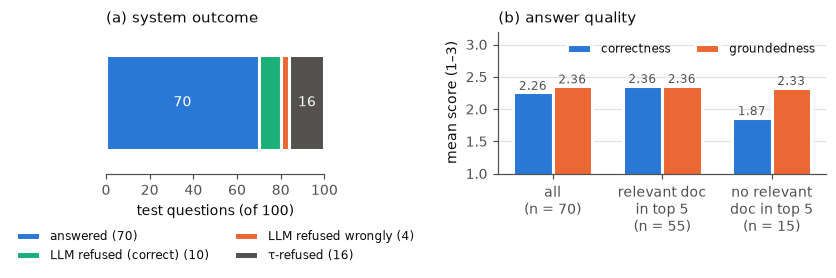

In [5]:
answered = [r for r in scores if r["outcome"] == "answered"]
groups = [("all", answered),
          ("relevant doc\nin top 5", [r for r in answered if r["gold_in_top5"]]),
          ("no relevant\ndoc in top 5", [r for r in answered if not r["gold_in_top5"]])]
mean = lambda rs, key: float(np.mean([int(r[key]) for r in rs]))

fig, (a, b) = plt.subplots(1, 2, figsize=(7.6, 2.9), gridspec_kw={"width_ratios": [1, 1.5]})

colors = [BLUE, AQUA, ORANGE, INK_2]
left = 0
for o, color in zip(order, colors):
    a.barh(0, counts[o], left=left, color=color, edgecolor="white", linewidth=2, label=f"{o} ({counts[o]})")
    if counts[o] >= 12:
        a.text(left + counts[o] / 2, 0, str(counts[o]), ha="center", va="center", color="white", fontsize=9)
    left += counts[o]
a.set_xlim(0, 100)
a.set_ylim(-0.6, 0.6)
a.set_yticks([])
a.grid(False)
a.spines["left"].set_visible(False)
a.set_xlabel("test questions (of 100)")
a.set_title("(a) system outcome", loc="left")
a.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2)

gx, w = np.arange(len(groups)), 0.36
for i, (key, label, color) in enumerate([("correctness_1to3", "correctness", BLUE),
                                         ("groundedness_1to3", "groundedness", ORANGE)]):
    v = [mean(rs, key) for _, rs in groups]
    bars = b.bar(gx + (i - 0.5) * w, v, w, color=color, edgecolor="white", linewidth=2, label=label)
    for bar, vi in zip(bars, v):
        b.text(bar.get_x() + bar.get_width() / 2, vi + 0.04, f"{vi:.2f}", ha="center", color=INK_2, fontsize=8)
b.set_xticks(gx, [f"{g}\n(n = {len(rs)})" for g, rs in groups])
b.set_ylim(1, 3.2)
b.set_yticks([1, 1.5, 2, 2.5, 3])
b.set_ylabel("mean score (1–3)")
b.set_title("(b) answer quality", loc="left")
b.legend(loc="upper right", ncol=2)
fig.tight_layout(w_pad=2.5)
save_figure(fig, "final_generation",
            "Final system on 100 FiQA test questions (config A, k = 5, τ = 0.60, gpt-oss-120b). (a) Outcome per "
            "question. (b) Mean correctness and groundedness (1–3) of the answered questions, split by whether a "
            "labelled relevant document was among the 5 given to the LLM. Scored by J and H together, with "
            "ChatGPT as a helper.")
plt.show()

In [6]:
def row(name, rs):
    return {"Subset": name, "n": len(rs), "Correctness": f"{mean(rs, 'correctness_1to3'):.2f}",
            "Groundedness": f"{mean(rs, 'groundedness_1to3'):.2f}"}

rows = [row("Answered by the system", answered),
        row("… relevant doc in top 5", [r for r in answered if r["gold_in_top5"]]),
        row("… no relevant doc in top 5", [r for r in answered if not r["gold_in_top5"]]),
        row("… answer hit the 400-token cap", [r for r in answered if r["truncated"]]),
        row("τ-refused, LLM answered anyway", [r for r in scores if r["outcome"] == "τ-refused"
                                               and REFUSAL_TEXT not in r["answer"]])]
rows.append({"Subset": "Dev reference (k = 5, 20 questions)", "n": 20, "Correctness": "2.53", "Groundedness": "2.87"})
print(save_table(rows, "final_generation"))
print(counts, "truncated (all 100):", sum(r["truncated"] for r in scores))

| Subset | n | Correctness | Groundedness |
|---|---|---|---|
| Answered by the system | 70 | 2.26 | 2.36 |
| … relevant doc in top 5 | 55 | 2.36 | 2.36 |
| … no relevant doc in top 5 | 15 | 1.87 | 2.33 |
| … answer hit the 400-token cap | 13 | 2.08 | 2.15 |
| τ-refused, LLM answered anyway | 7 | 2.29 | 2.57 |
| Dev reference (k = 5, 20 questions) | 20 | 2.53 | 2.87 |

{'answered': 70, 'LLM refused (correct)': 10, 'LLM refused wrongly': 4, 'τ-refused': 16} truncated (all 100): 14


## Findings (J and H — edit in your own words before the report)

- **Dev conclusions hold on test.** Both configs drop a little (A Recall@10 0.4665 → 0.4413, B 0.4178 → 0.3878),
  as expected after choosing settings on dev; B stays about 5 pt below A (−5.35 pt) at 3× less memory.
- **The final system answers 70 of 100 test questions** (16 refused by τ, 14 refused by the LLM itself);
  test answer rate at τ is 0.84 (dev 0.76, but dev used a reduced corpus).
- **Retrieval errors show up as low correctness, not low groundedness:** without a relevant doc in the top 5,
  correctness drops (≈ 1.9 vs ≈ 2.4) while groundedness stays the same — the LLM stays faithful to the wrong
  documents. Better retrieval would help more than a better prompt.
- **Limitations:** test latency of A inflated by background load (use dev 30×); 14 answers hit the 400-token
  output cap; dev and test scores were both made by J and H with ChatGPT as a helper (same procedure, so
  dev vs. test quality is comparable, but scores are AI-assisted); no inter-rater agreement (one joint score); correct refusal only from 10 dev questions.